In [1]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [8]:
df = pd.read_csv('../../data/tested.csv', usecols=['Age', 'Fare', 'Survived'])

In [9]:
df.head()

,Survived,Age,Fare
0,0,34.5,7.8292
1,1,47.0,7.0000
2,0,62.0,9.6875
3,0,27.0,8.6625
4,1,22.0,12.2875


In [19]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [17]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Fare'] = df['Fare'].fillna(df['Fare'].mean())


In [18]:
df.head()

,Survived,Age,Fare
0,0,34.5,7.8292
1,1,47.0,7.0000
2,0,62.0,9.6875
3,0,27.0,8.6625
4,1,22.0,12.2875


In [20]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]


In [21]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)


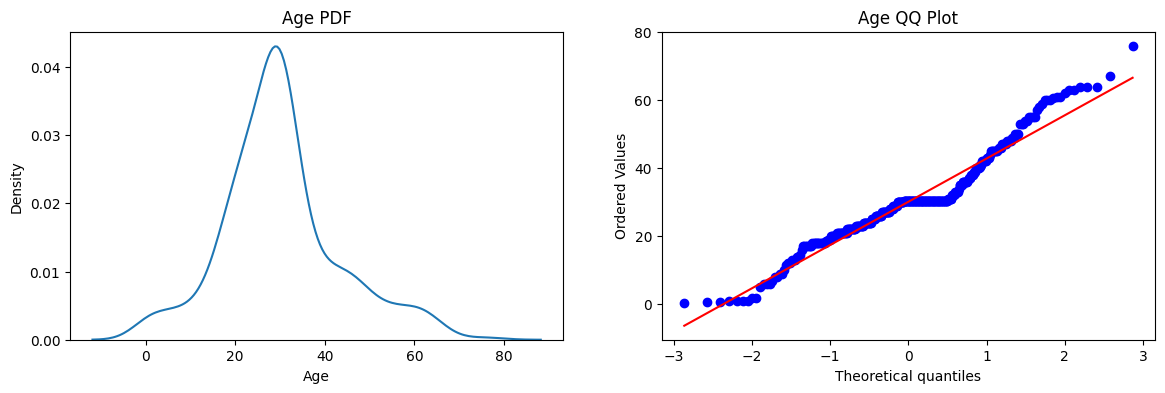

In [23]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.kdeplot(X_train['Age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

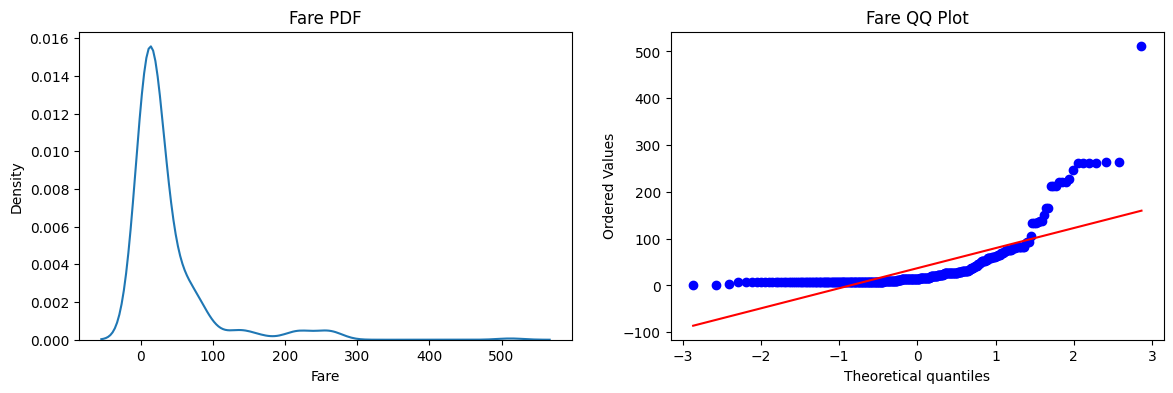

In [25]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.kdeplot(X_train['Fare'])
plt.title('Fare PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Fare QQ Plot')

plt.show()

In [26]:

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()


In [27]:
clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)
    
y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6071428571428571
Accuracy DT 0.5476190476190477


- What if I transform the column ?
- # with Log transformation

In [28]:
trf= FunctionTransformer(func=np.log1p)

In [29]:

X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [30]:

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)
    
y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))


Accuracy LR 0.6190476190476191
Accuracy DT 0.5595238095238095


# Cross validation


In [31]:
X_transformed=trf.fit_transform(X)
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf,X_transformed,y,scoring="accuracy",cv=10)))
print("DT",np.mean(cross_val_score(clf2,X_transformed,y,scoring="accuracy",cv=10)))

LR 0.6556329849012775
DT 0.6053426248548199


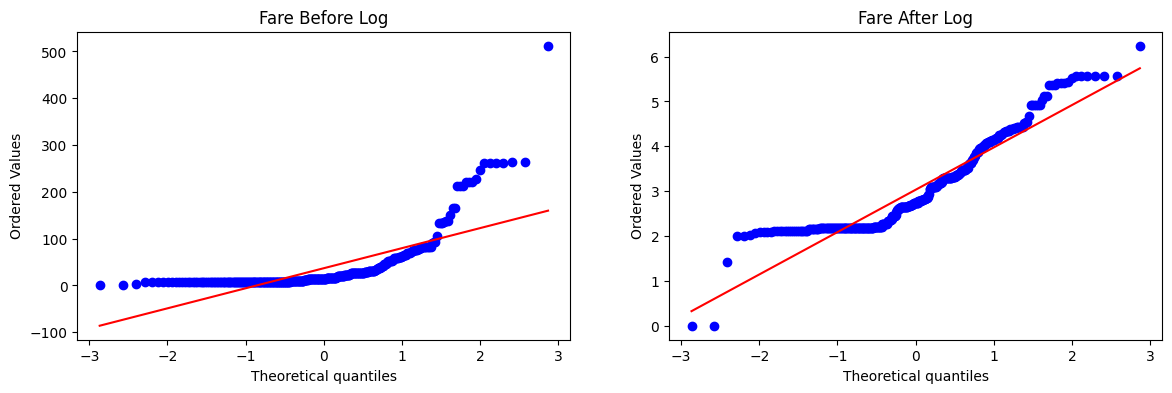

In [32]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist="norm", plot=plt)
plt.title('Fare After Log')

plt.show()

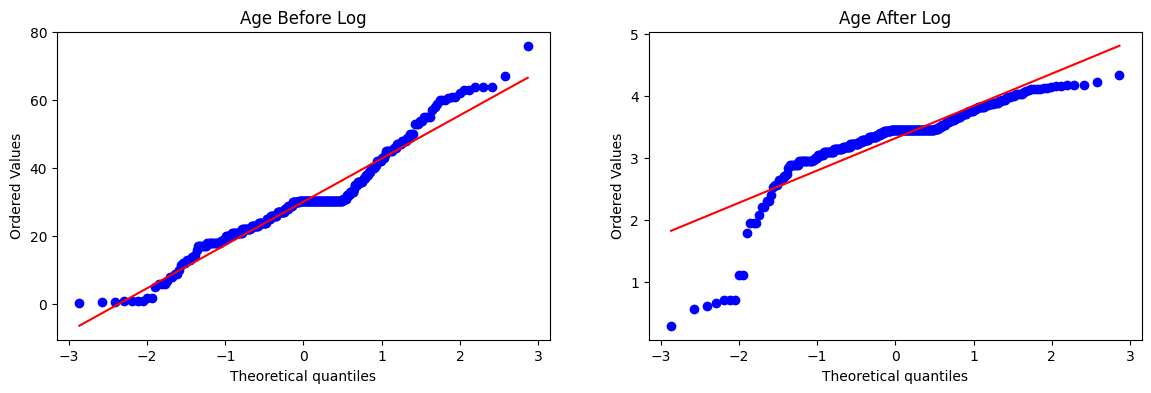

In [33]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist="norm", plot=plt)
plt.title('Age After Log')

plt.show()

In [34]:
# Making the column transformer for trying log transformation in just the fare not the age 
trf2 = ColumnTransformer([('log',FunctionTransformer(np.log1p),['Fare'])],remainder='passthrough')

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

In [35]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2,y_train)
clf2.fit(X_train_transformed2,y_train)
    
y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.6190476190476191
Accuracy DT 0.5476190476190477


In [42]:
#Lets do the same using the pipeline and cross validating them .

# Transform Fare only
trf2 = ColumnTransformer(
    [('log', FunctionTransformer(np.log1p), ['Fare'])],
    remainder='passthrough'
)

# Transform both Age and Fare
trf_all = FunctionTransformer(np.log1p)

models = {
    "LR - Fare only": make_pipeline(
        trf2, LogisticRegression(max_iter=1000)
    ),
    "LR - Both": make_pipeline(
        trf_all, LogisticRegression(max_iter=1000)
    ),
    "DT - Fare only": make_pipeline(
        trf2, DecisionTreeClassifier(random_state=42)
    ),
    "DT - Both": make_pipeline(
        trf_all, DecisionTreeClassifier(random_state=42)
    )
}

for name, model in models.items():
    scores = cross_val_score(
        model, X, y, cv=10, scoring="accuracy"
    )
    print(name, scores.mean())

LR - Fare only 0.6507549361207897
LR - Both 0.6556329849012775
DT - Fare only 0.5861788617886179
DT - Both 0.5981416957026713


In [43]:
def apply_transform(transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]
    
    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    X_trans = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print("Accuracy",np.mean(cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))
    
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()
    

Accuracy 0.6363530778164923


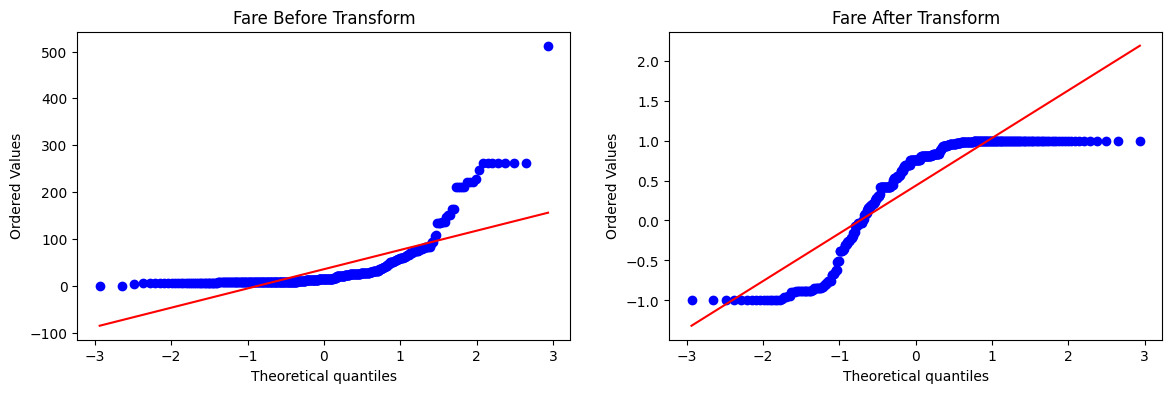

In [44]:
apply_transform(np.sin)


Accuracy 0.6506968641114981


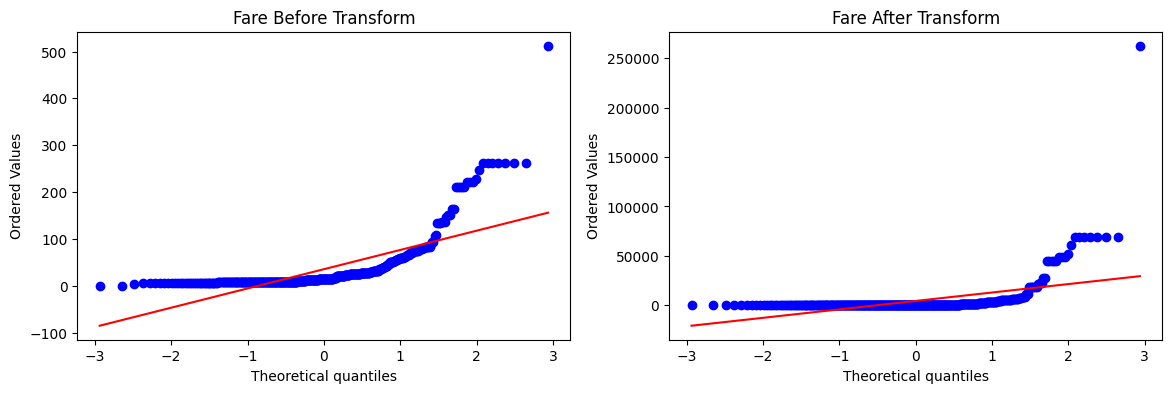

In [46]:
apply_transform(lambda x: x**2)


Accuracy 0.6363530778164923


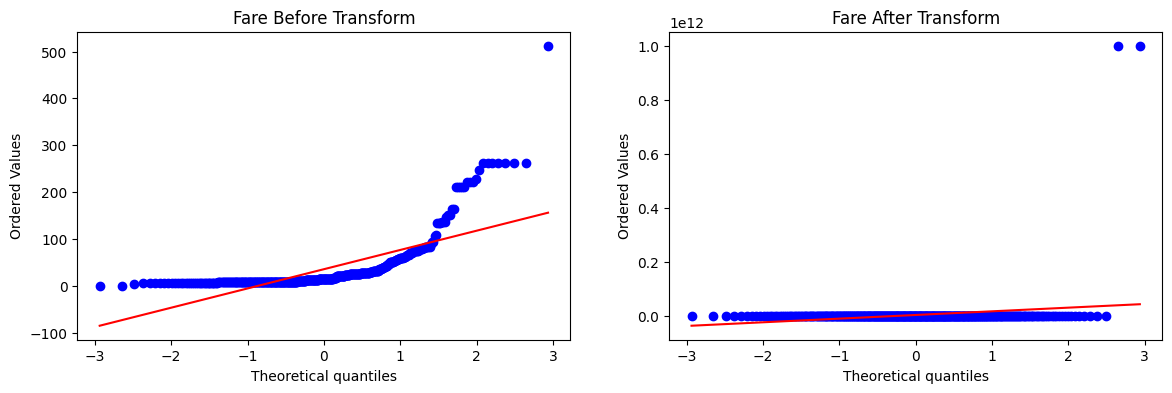

In [47]:
apply_transform(lambda x: 1/(x+0.000000000001))
